# House Price Prediction Using Supervised Learning

## Part A: Problem Framing & Theory Notes

### A.1 Regression vs Classification
- **Regression** predicts a continuous number, such as a house's selling price.
- **Classification** predicts a class/category, such as whether a customer will buy a house.
- Indian examples of regression: predicting a home's price in Mumbai or crop yield per acre in Maharashtra.
- Indian examples of classification: predicting loan default (yes/no) or whether a customer will churn.

### A.2 Simple, Multiple and Regularised Regression
- **Simple Linear Regression** uses one input feature to predict the target.
- **Multiple Linear Regression** uses two or more input features.
- **Ridge Regression (L2)** penalises large coefficients and usually shrinks them toward zero.
- **Lasso Regression (L1)** can shrink some coefficients exactly to zero, performing feature selection.

### A.3 Overfitting, Underfitting and Regularisation
- **Overfitting:** model learns training-specific patterns/noise and performs worse on unseen data.
- **Underfitting:** model is too simple to capture important relationships.
- Regularisation adds a penalty for model complexity and can improve generalisation.
- Ridge uses an L2 penalty; Lasso uses an L1 penalty.

### A.4 Regression Metrics
- **MAE:** average absolute prediction error; easy to explain in USD.
- **RMSE:** square root of mean squared error; penalises large errors more strongly.
- **R²:** proportion of target variation explained by the model (can be negative on poor test predictions).
- We train on `log1p(SalePrice)` to reduce skew, then use `expm1()` to calculate MAE/RMSE in original USD.

### A.5 K-Fold Cross-Validation
- K-Fold divides training data into K folds.
- The model is trained K times, using one fold for validation and the other folds for training.
- It gives a more stable performance estimate than relying on one split alone.
- Cross-validation must be performed on the training set; the test set is reserved for final evaluation.

## Part B: Data Loading & Exploratory Data Analysis (EDA)

### B.1 Load and Understand the Dataset


In [1]:
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score, RandomizedSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
import joblib

In [2]:
df = pd.read_csv(r"C:\Users\tanaa\Downloads\train.csv")
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [4]:
display(df.describe())

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [5]:
df.shape

(1460, 81)

In [6]:
# Identify numerical and categorical columns
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(include=["object"]).columns.tolist()

print("Numerical columns:", len(numerical_columns))
print("Categorical columns:", len(categorical_columns))
print("Duplicate rows:", df.duplicated().sum())

Numerical columns: 38
Categorical columns: 43
Duplicate rows: 0


In [7]:
# Missing-value report
missing_report = pd.DataFrame({
    "Missing Values": df.isna().sum(),
    "Missing Percentage": (df.isna().sum() / len(df) * 100).round(2)
})
missing_report = missing_report[missing_report["Missing Values"] > 0].sort_values(
    "Missing Percentage", ascending=False
)
display(missing_report)

,Missing Values,Missing Percentage
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


### B.2 Univariate Analysis

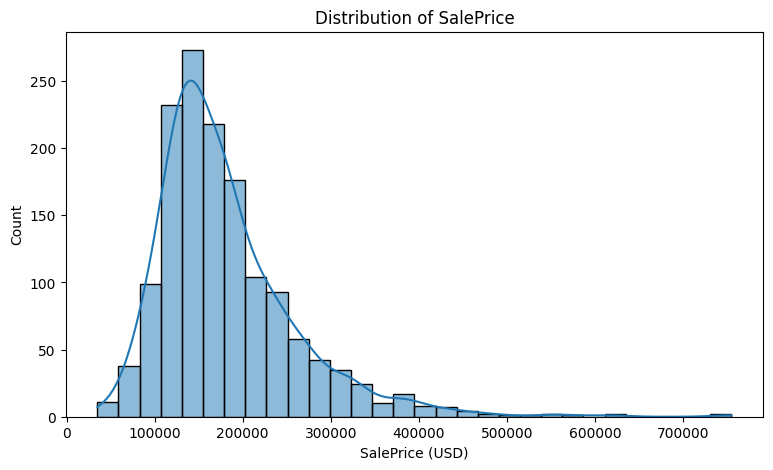

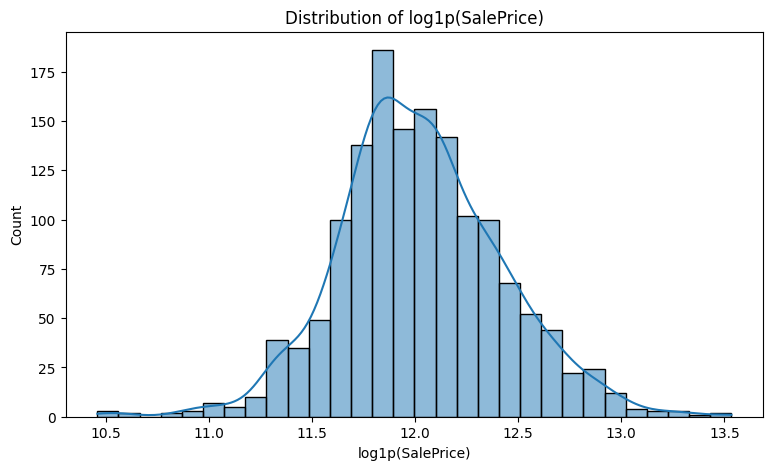

In [8]:
plt.figure(figsize=(9, 5))
sns.histplot(df["SalePrice"], bins=30, kde=True)
plt.title("Distribution of SalePrice")
plt.xlabel("SalePrice (USD)")
plt.show()

# Log-transformed target distribution
plt.figure(figsize=(9, 5))
sns.histplot(np.log1p(df["SalePrice"]), bins=30, kde=True)
plt.title("Distribution of log1p(SalePrice)")
plt.xlabel("log1p(SalePrice)")
plt.show()

In [10]:
# Top 5 most skewed numeric columns (absolute skewness)
skew_values = df[numerical_columns].skew(numeric_only=True)
top_5_skewed = skew_values.abs().sort_values(ascending=False).head(5)
print("Top 5 most skewed numerical columns (absolute skewness):")
display(pd.DataFrame({"Absolute Skewness": top_5_skewed}))

Top 5 most skewed numerical columns (absolute skewness):


,Absolute Skewness
MiscVal,24.476794
PoolArea,14.828374
LotArea,12.207688
3SsnPorch,10.304342
LowQualFinSF,9.011341


### B.3 Bivariate Analysis


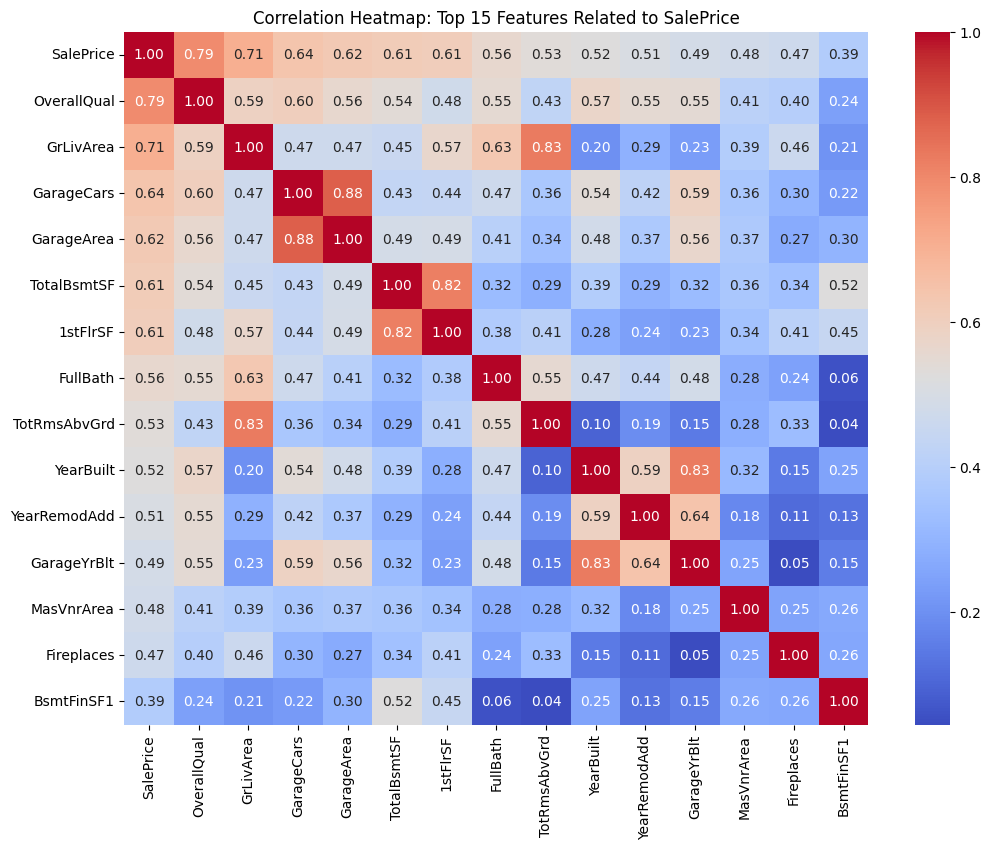

In [12]:
# Correlation heatmap for the 15 numerical features most correlated with SalePrice
corr = df.select_dtypes(include=np.number).corr()
top_corr_features = corr["SalePrice"].abs().sort_values(ascending=False).head(15).index

plt.figure(figsize=(12, 9))
sns.heatmap(df[top_corr_features].corr(), cmap="coolwarm", annot=True, fmt=".2f")
plt.title("Correlation Heatmap: Top 15 Features Related to SalePrice")
plt.show()

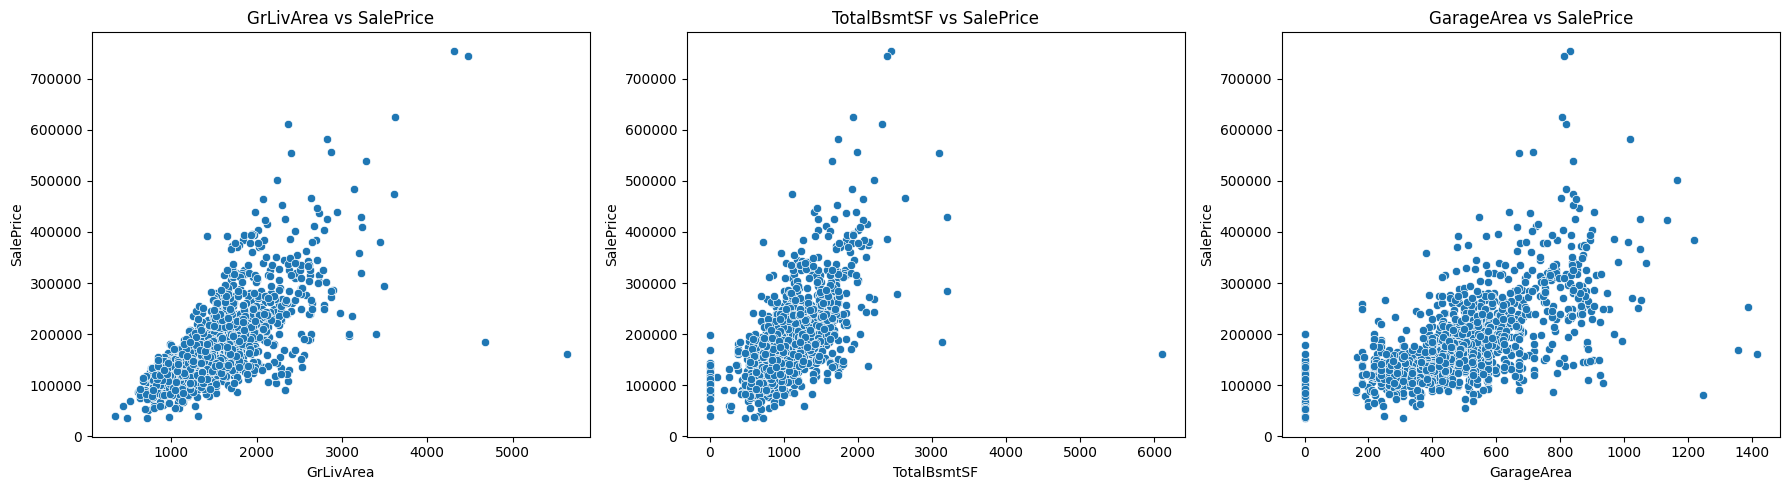

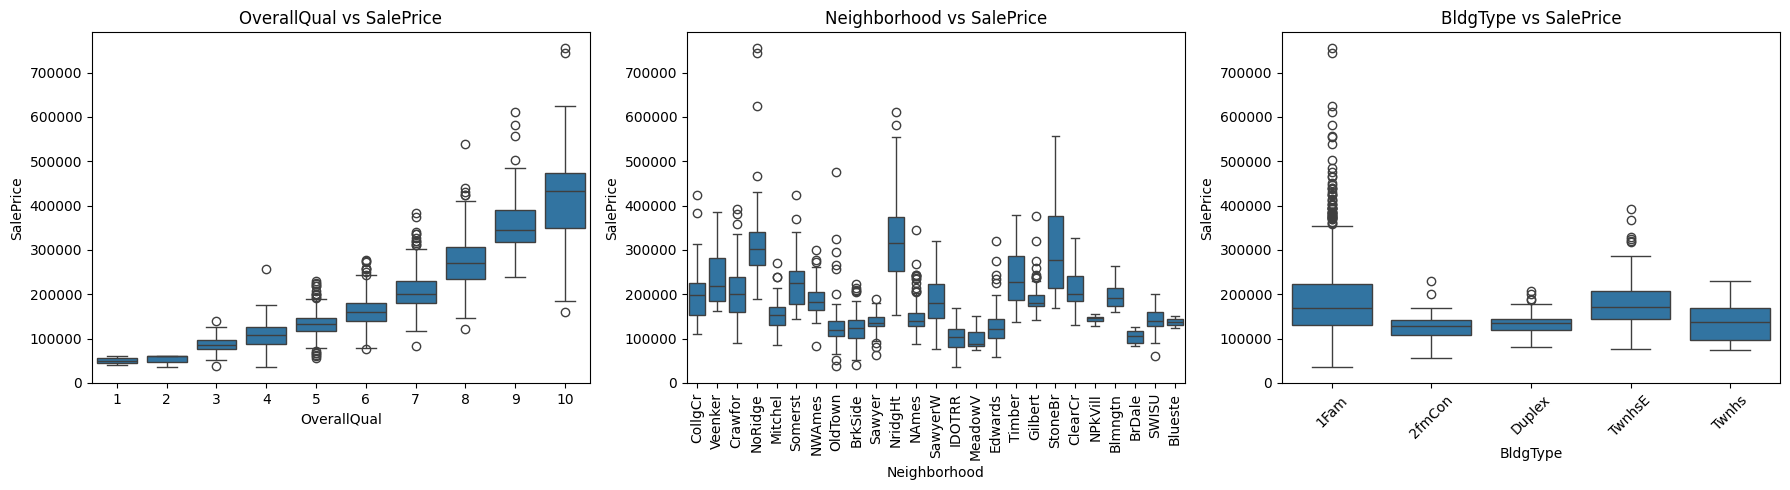

In [13]:
# Scatter plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", ax=axes[0])
axes[0].set_title("GrLivArea vs SalePrice")
sns.scatterplot(data=df, x="TotalBsmtSF", y="SalePrice", ax=axes[1])
axes[1].set_title("TotalBsmtSF vs SalePrice")
sns.scatterplot(data=df, x="GarageArea", y="SalePrice", ax=axes[2])
axes[2].set_title("GarageArea vs SalePrice")
plt.tight_layout()
plt.show()

# Boxplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=df, x="OverallQual", y="SalePrice", ax=axes[0])
axes[0].set_title("OverallQual vs SalePrice")
sns.boxplot(data=df, x="Neighborhood", y="SalePrice", ax=axes[1])
axes[1].set_title("Neighborhood vs SalePrice")
axes[1].tick_params(axis="x", rotation=90)
sns.boxplot(data=df, x="BldgType", y="SalePrice", ax=axes[2])
axes[2].set_title("BldgType vs SalePrice")
axes[2].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [14]:
# Flag unusual large living-area houses with comparatively low sale prices
outlier_candidates = df[(df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)]
display(outlier_candidates[["Id", "GrLivArea", "SalePrice"]])
print("Number of flagged rows:", len(outlier_candidates))

,Id,GrLivArea,SalePrice
523,524,4676,184750
1298,1299,5642,160000


Number of flagged rows: 2


## Part C: Data Preprocessing & Feature Engineering

We split the data before fitting transformations to avoid data leakage. All imputers, encoders, and scalers are fitted on the training data only through a scikit-learn Pipeline.

### C.1 Handle Missing Values
- For categorical fields where missing means absence (such as PoolQC, Fence, GarageType, and FireplaceQu), use "None".
- For numeric fields where missing means no feature (for example GarageArea or BsmtFinSF1), fill with 0.
- Remaining numerical missing values use the training median; remaining categorical missing values use the most frequent category.
- Columns with more than 80% missing values are dropped, based on the training data.

### C.2 Outlier Removal
The assignment asks to remove records where GrLivArea > 4000 and SalePrice < 300000. These unusually large homes with low sale prices can exert disproportionate influence on a linear model. We apply this rule to the training data only; test data remains untouched.

### C.3 Feature Engineering
- TotalSF = total basement area + first floor area + second floor area.
- HouseAge = year sold − year built.
- RemodAge = year sold − year remodeled.
- HasGarage = 1 if garage area is positive, otherwise 0.
- HasPool = 1 if pool area is positive, otherwise 0.

In [17]:
# Remove duplicate rows
data = df.drop_duplicates().copy()

# Drop ID column
if "Id" in data.columns:
    data = data.drop(columns=["Id"])

# Create new features
data["TotalSF"] = data["TotalBsmtSF"].fillna(0) + data["1stFlrSF"] + data["2ndFlrSF"]
data["HouseAge"] = data["YrSold"] - data["YearBuilt"]
data["RemodAge"] = data["YrSold"] - data["YearRemodAdd"]

# Separate features and target
X = data.drop(columns=["SalePrice"])
y = data["SalePrice"]

# Split data into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1168, 82)
Testing data: (292, 82)


### C.4 Encoding and Scaling
- Ordinal columns have a meaningful order (quality/condition ratings), so we map them to ordered numbers.
- Nominal categorical columns are One-Hot Encoded. handle_unknown="ignore" allows unseen test categories.
- Numeric features are median-imputed and standardised.
- Preprocessing is placed inside a ColumnTransformer and Pipeline to ensure the same operations are applied at training and prediction time.

**Note:** We use a practical, reproducible encoding pipeline. One-hot encoding is also applied to Neighborhood; this avoids imposing an artificial numeric order on neighborhoods.

In [18]:
# Ordinal mappings: lower quality/condition to higher quality/condition
ordinal_mappings = {
    "ExterQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "ExterCond": ["Po", "Fa", "TA", "Gd", "Ex"],
    "BsmtQual": ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    "BsmtCond": ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    "HeatingQC": ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "FireplaceQu": ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    "GarageQual": ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    "GarageCond": ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    "PoolQC": ["None", "Fa", "TA", "Gd", "Ex"],
    "BsmtExposure": ["None", "No", "Mn", "Av", "Gd"],
    "BsmtFinType1": ["None", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "BsmtFinType2": ["None", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "Functional": ["Sal", "Sev", "Maj2", "Maj1", "Mod", "Min2", "Min1", "Typ"],
    "Fence": ["None", "MnWw", "GdWo", "MnPrv", "GdPrv"],
}

# Apply mappings where the column exists; unknown categories become NaN and are imputed later
for col, order in ordinal_mappings.items():
    if col in X_train.columns:
        mapping = {category: rank for rank, category in enumerate(order)}
        X_train[col] = X_train[col].map(mapping)
        X_test[col] = X_test[col].map(mapping)

# Categorical absence indicators: missing means the feature is absent
absence_categories = [
    "Alley", "MasVnrType", "BsmtQual", "BsmtCond", "BsmtExposure",
    "BsmtFinType1", "BsmtFinType2", "FireplaceQu", "GarageType",
    "GarageFinish", "GarageQual", "GarageCond", "PoolQC", "Fence",
    "MiscFeature"
]
for col in absence_categories:
    if col in X_train.columns and col not in ordinal_mappings:
        X_train[col] = X_train[col].fillna("None")
        X_test[col] = X_test[col].fillna("None")

# Numeric missing values where absence means zero
zero_fill_columns = ["GarageArea", "GarageCars", "BsmtFinSF1", "BsmtFinSF2",
                     "BsmtUnfSF", "TotalBsmtSF", "MasVnrArea", "PoolArea"]
for col in zero_fill_columns:
    if col in X_train.columns:
        X_train[col] = X_train[col].fillna(0)
        X_test[col] = X_test[col].fillna(0)

# Drop columns with >80% missing values, based on training set
high_missing_columns = X_train.columns[X_train.isna().mean() > 0.80].tolist()
print("Dropped columns (>80% missing):", high_missing_columns)
X_train = X_train.drop(columns=high_missing_columns)
X_test = X_test.drop(columns=high_missing_columns)

# Detect remaining numeric and categorical columns
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Preprocessing object created.")

Dropped columns (>80% missing): ['PoolQC', 'Fence']
Numeric features: 52
Categorical features: 28
Preprocessing object created.


### C.5 Train-Test Split and Target Transformation
- We use an 80% training and 20% testing split with random_state=42.
- The target is transformed with log1p during model fitting.
- Predictions are transformed back with expm1 before reporting RMSE, MAE, and R² in USD.

## Part D: Regression Models — Linear, Ridge & Lasso

We train three baseline/regularised regression models using the same preprocessing pipeline. RidgeCV and LassoCV select a suitable regularisation strength using internal cross-validation on the training set.

In [20]:
def make_model(regressor):
    # Target transformation is learned/applied only during model fitting
    return TransformedTargetRegressor(
        regressor=Pipeline(steps=[
            ("preprocessor", clone(preprocessor)),
            ("model", regressor)
        ]),
        func=np.log1p,
        inverse_func=np.expm1
    )

def evaluate_model(model, X_eval, y_eval):
    predictions = model.predict(X_eval)
    return {
        "RMSE": np.sqrt(mean_squared_error(y_eval, predictions)),
        "MAE": mean_absolute_error(y_eval, predictions),
        "R2 Score": r2_score(y_eval, predictions)
    }

results = []
fitted_models = {}
training_times = {}

# Linear Regression
linear_model = make_model(LinearRegression())
start = time.time()
linear_model.fit(X_train, y_train)
training_times["Linear Regression"] = time.time() - start
fitted_models["Linear Regression"] = linear_model
linear_metrics = evaluate_model(linear_model, X_test, y_test)
results.append({"Model": "Linear Regression", **linear_metrics,
                "5-Fold CV RMSE": np.nan,
                "Training Time (seconds)": training_times["Linear Regression"]})

print("Linear Regression:", linear_metrics)

Linear Regression: {'RMSE': np.float64(22793.836256806942), 'MAE': 15084.876140662791, 'R2 Score': 0.9322637711528751}


In [21]:
# Ridge Regression with cross-validated alpha selection
ridge_model = make_model(RidgeCV(alphas=[0.01, 0.1, 1, 10, 100], cv=5))
start = time.time()
ridge_model.fit(X_train, y_train)
training_times["Ridge"] = time.time() - start
fitted_models["Ridge"] = ridge_model
ridge_metrics = evaluate_model(ridge_model, X_test, y_test)

ridge_alpha = ridge_model.regressor_.named_steps["model"].alpha_
print("Best Ridge alpha:", ridge_alpha)
print("Ridge metrics:", ridge_metrics)

Best Ridge alpha: 10.0
Ridge metrics: {'RMSE': np.float64(25236.473613959377), 'MAE': 16278.344769918072, 'R2 Score': 0.9169683813614982}


In [22]:
# Lasso Regression with cross-validated alpha selection
lasso_model = make_model(LassoCV(
    alphas=[0.0001, 0.001, 0.01, 0.1, 1],
    max_iter=10000,
    cv=5,
    random_state=RANDOM_STATE
))
start = time.time()
lasso_model.fit(X_train, y_train)
training_times["Lasso"] = time.time() - start
fitted_models["Lasso"] = lasso_model
lasso_metrics = evaluate_model(lasso_model, X_test, y_test)

lasso_alpha = lasso_model.regressor_.named_steps["model"].alpha_
print("Best Lasso alpha:", lasso_alpha)
print("Lasso metrics:", lasso_metrics)

Best Lasso alpha: 0.001
Lasso metrics: {'RMSE': np.float64(25124.40514399036), 'MAE': 16176.8762731086, 'R2 Score': 0.9177041866553344}


In [23]:
# Compare Ridge and Lasso performance
print("Ridge vs Lasso")
print("Ridge R2:", ridge_metrics["R2 Score"])
print("Lasso R2:", lasso_metrics["R2 Score"])
print("Lower RMSE is better.")

Ridge vs Lasso
Ridge R2: 0.9169683813614982
Lasso R2: 0.9177041866553344
Lower RMSE is better.


## Part E: Advanced Models — Random Forest & XGBoost Regressor

Tree-based models can capture non-linear relationships and interactions between house features. We evaluate Random Forest and XGBoost (if installed).

In [24]:
# Random Forest
rf_model = make_model(RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    random_state=RANDOM_STATE,
    n_jobs=-1
))
start = time.time()
rf_model.fit(X_train, y_train)
training_times["Random Forest"] = time.time() - start
fitted_models["Random Forest"] = rf_model
rf_metrics = evaluate_model(rf_model, X_test, y_test)
results.append({"Model": "Random Forest", **rf_metrics,
                "5-Fold CV RMSE": np.nan,
                "Training Time (seconds)": training_times["Random Forest"]})
print("Random Forest metrics:", rf_metrics)

Random Forest metrics: {'RMSE': np.float64(29720.825075884317), 'MAE': 17267.602701738673, 'R2 Score': 0.8848383472447844}


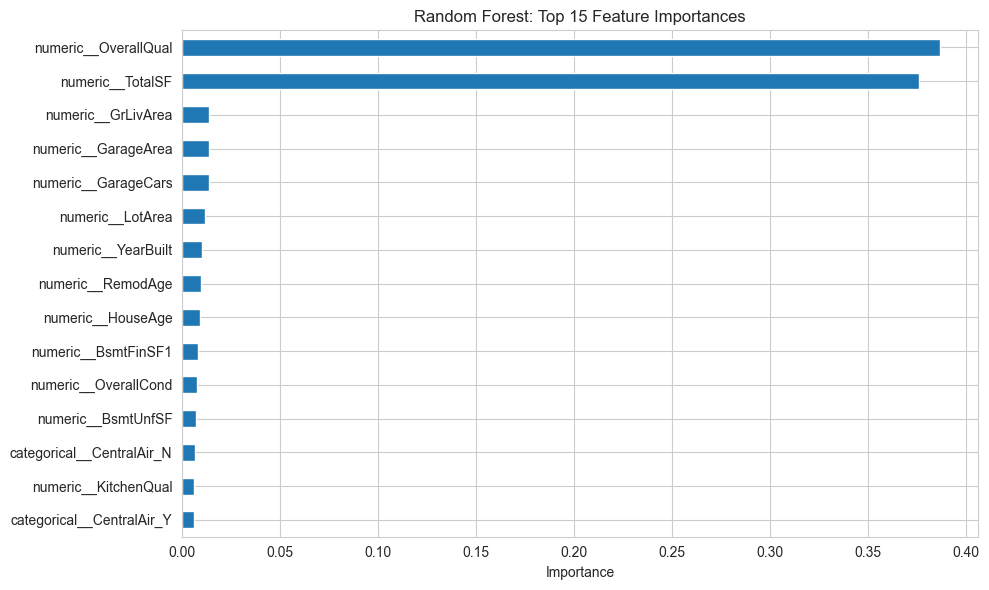

In [25]:
# Random Forest feature importance (top 15)
rf_pipeline = rf_model.regressor_
rf_preprocessor = rf_pipeline.named_steps["preprocessor"]
rf_estimator = rf_pipeline.named_steps["model"]
rf_feature_names = rf_preprocessor.get_feature_names_out()

rf_importance = pd.Series(
    rf_estimator.feature_importances_,
    index=rf_feature_names
).sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
rf_importance.sort_values().plot(kind="barh")
plt.title("Random Forest: Top 15 Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [26]:
# XGBoost (install xgboost if it is not available: %pip install xgboost)
try:
    from xgboost import XGBRegressor

    xgb_model = make_model(XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=RANDOM_STATE,
        objective="reg:squarederror",
        n_jobs=-1
    ))

    start = time.time()
    xgb_model.fit(X_train, y_train)
    training_times["XGBoost"] = time.time() - start
    fitted_models["XGBoost"] = xgb_model
    xgb_metrics = evaluate_model(xgb_model, X_test, y_test)
    results.append({"Model": "XGBoost", **xgb_metrics,
                    "5-Fold CV RMSE": np.nan,
                    "Training Time (seconds)": training_times["XGBoost"]})
    print("XGBoost metrics:", xgb_metrics)

except ImportError:
    xgb_model = None
    print("XGBoost is not installed. Run %pip install xgboost, restart the kernel, and rerun this cell.")

XGBoost is not installed. Run %pip install xgboost, restart the kernel, and rerun this cell.


### E.3 Cross-Validation on the Best Model So Far
We select the current best model by test RMSE for demonstration. For a rigorous workflow, model selection should be based on training cross-validation, with the test set used only once for final evaluation. The scoring below is negative RMSE on the log-transformed target, as is standard for this competition-style target.

In [27]:
# 5-fold CV on training data for the best currently available model
current_best_name = min(
    fitted_models,
    key=lambda name: evaluate_model(fitted_models[name], X_test, y_test)["RMSE"]
)
current_best_model = fitted_models[current_best_name]
print("Current best model (based on test RMSE for this exam comparison):", current_best_name)

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(
    current_best_model,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=1
)
cv_rmse_scores = -cv_scores
print("5-Fold CV RMSE on log-target scale — mean:", cv_rmse_scores.mean())
print("5-Fold CV RMSE on log-target scale — std:", cv_rmse_scores.std())
print("Note: this CV score is in log-target units, not original USD.")

Current best model (based on test RMSE for this exam comparison): Linear Regression
5-Fold CV RMSE on log-target scale — mean: 49237.74675604777
5-Fold CV RMSE on log-target scale — std: 34227.411497748995
Note: this CV score is in log-target units, not original USD.


### E.4 Hyperparameter Tuning
We use RandomizedSearchCV to tune at least two Random Forest hyperparameters. The search uses training folds only. The best estimator is then evaluated on the held-out test set.

In [28]:
# Randomized Search for Random Forest
rf_search_base = make_model(RandomForestRegressor(
    random_state=RANDOM_STATE,
    n_jobs=-1
))

param_distributions = {
    "regressor__model__n_estimators": [150, 250, 400],
    "regressor__model__max_depth": [None, 8, 12, 16],
    "regressor__model__min_samples_split": [2, 5, 10],
    "regressor__model__min_samples_leaf": [1, 2, 4]
}

random_search = RandomizedSearchCV(
    estimator=rf_search_base,
    param_distributions=param_distributions,
    n_iter=10,
    cv=3,
    scoring="neg_root_mean_squared_error",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

start = time.time()
random_search.fit(X_train, y_train)
tuned_rf_time = time.time() - start

tuned_model = random_search.best_estimator_
tuned_metrics = evaluate_model(tuned_model, X_test, y_test)

print("Best parameters:", random_search.best_params_)
print("Best CV RMSE (log target):", -random_search.best_score_)
print("Tuned Random Forest test metrics (USD scale):", tuned_metrics)

fitted_models["Tuned Random Forest"] = tuned_model
training_times["Tuned Random Forest"] = tuned_rf_time
results.append({"Model": "Tuned Random Forest", **tuned_metrics,
                "5-Fold CV RMSE": -random_search.best_score_,
                "Training Time (seconds)": tuned_rf_time})

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best parameters: {'regressor__model__n_estimators': 400, 'regressor__model__min_samples_split': 2, 'regressor__model__min_samples_leaf': 1, 'regressor__model__max_depth': 16}
Best CV RMSE (log target): 28865.77389492854
Tuned Random Forest test metrics (USD scale): {'RMSE': np.float64(29905.584260460688), 'MAE': 17287.91713757639, 'R2 Score': 0.8834020945391462}


## Part F: Model Evaluation & Comparison

We prepare a consolidated table containing RMSE, MAE, R², cross-validation RMSE where available, and training time. RMSE and MAE are in the original SalePrice (USD) scale.

In [29]:
# Add Ridge and Lasso to comparison results
results.extend([
    {"Model": "Ridge", **ridge_metrics,
     "5-Fold CV RMSE": np.nan,
     "Training Time (seconds)": training_times["Ridge"]},
    {"Model": "Lasso", **lasso_metrics,
     "5-Fold CV RMSE": np.nan,
     "Training Time (seconds)": training_times["Lasso"]}
])

comparison_df = pd.DataFrame(results)
comparison_df = comparison_df.drop_duplicates(subset=["Model"], keep="last")
comparison_df = comparison_df.sort_values("RMSE").reset_index(drop=True)
display(comparison_df.round(3))

,Model,RMSE,MAE,R2 Score,5-Fold CV RMSE,Training Time (seconds)
0,Linear Regression,22793.836,15084.876,0.932,NaN,0.270
1,Lasso,25124.405,16176.876,0.918,NaN,1.388
2,Ridge,25236.474,16278.345,0.917,NaN,0.544
3,Random Forest,29720.825,17267.603,0.885,NaN,1.857
4,Tuned Random Forest,29905.584,17287.917,0.883,28865.774,54.492


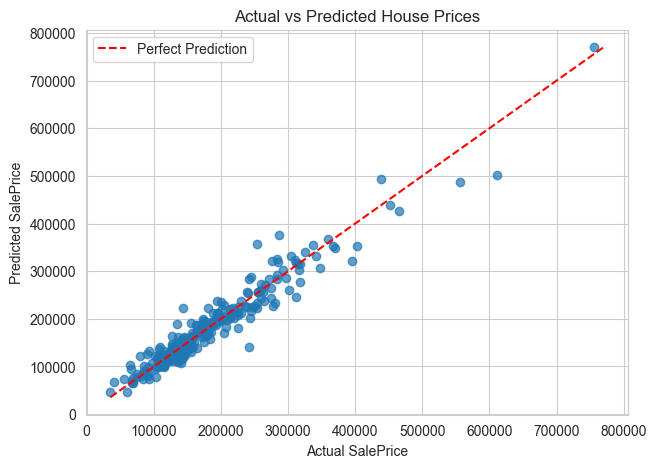

In [33]:
# Actual vs Predicted plot
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred, alpha=0.7)

# Perfect prediction line
lims = [
    min(y_test.min(), y_pred.min()),
    max(y_test.max(), y_pred.max())
]

plt.plot(lims, lims, "r--", label="Perfect Prediction")

plt.xlabel("Actual SalePrice")
plt.ylabel("Predicted SalePrice")
plt.title("Actual vs Predicted House Prices")

plt.legend()
plt.show()

## Part G: Residual Analysis & Model Interpretation

A residual is actual price − predicted price. Residual diagnostics help identify systematic errors and possible violations of model assumptions.

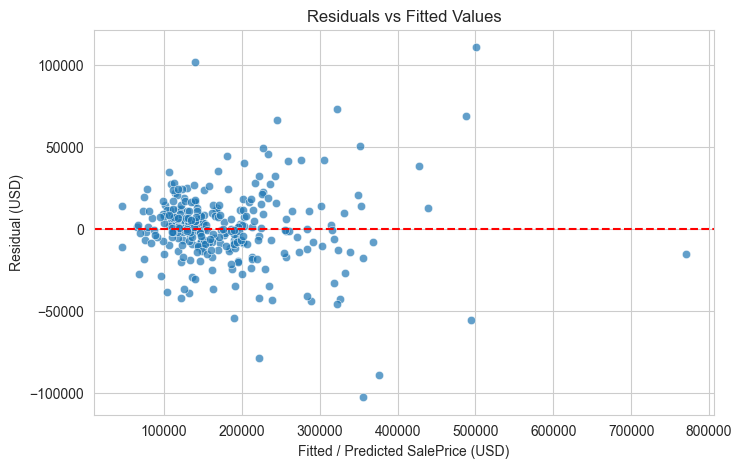

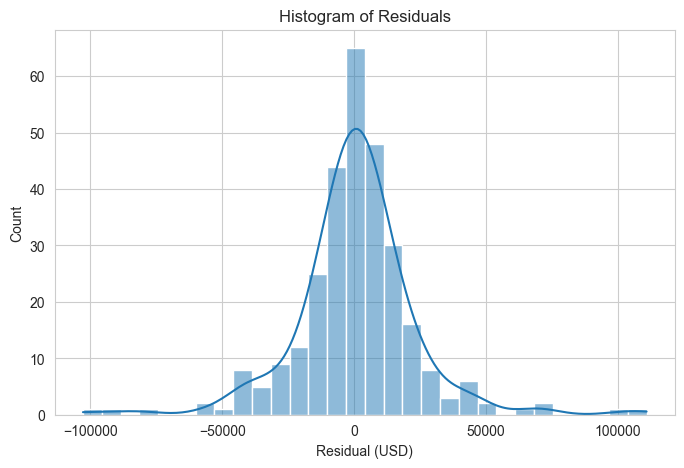

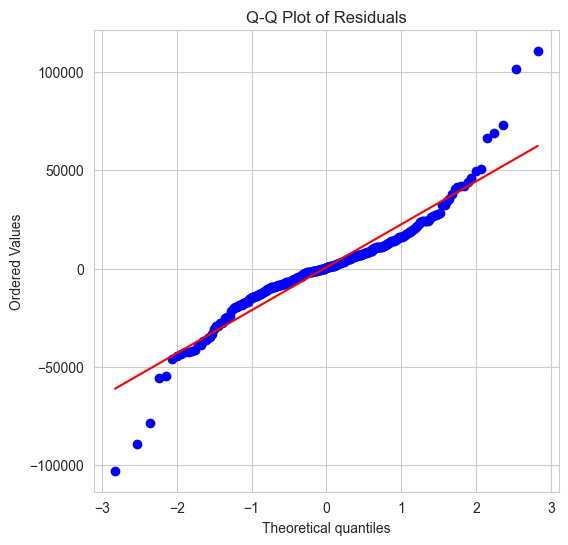

Mean residual: 698.4697786308253
Median residual: 501.9295432600484


In [35]:
residuals = y_test - best_predictions

plt.figure(figsize=(8, 5))
sns.scatterplot(x=best_predictions, y=residuals, alpha=0.7)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Fitted / Predicted SalePrice (USD)")
plt.ylabel("Residual (USD)")
plt.title("Residuals vs Fitted Values")
plt.show()

plt.figure(figsize=(8, 5))
sns.histplot(residuals, bins=30, kde=True)
plt.title("Histogram of Residuals")
plt.xlabel("Residual (USD)")
plt.show()

# Q-Q plot
from scipy import stats
plt.figure(figsize=(6, 6))
stats.probplot(residuals, dist="norm", plot=plt)
plt.title("Q-Q Plot of Residuals")
plt.show()

print("Mean residual:", residuals.mean())
print("Median residual:", residuals.median())

In [36]:
# G.2 Business Interpretation — Top 5 Features

# Feature importance is directly available for tree-based estimators.
# For a linear model, absolute coefficients can be inspected instead.
best_pipeline = best_model.regressor_
best_preprocessor = best_pipeline.named_steps["preprocessor"]
best_estimator = best_pipeline.named_steps["model"]
feature_names = best_preprocessor.get_feature_names_out()

if hasattr(best_estimator, "feature_importances_"):
    importance_values = best_estimator.feature_importances_
    top_features = pd.Series(importance_values, index=feature_names).sort_values(ascending=False).head(5)
    print("Top 5 features by model importance:")
    display(top_features)
elif hasattr(best_estimator, "coef_"):
    coefficients = pd.Series(best_estimator.coef_, index=feature_names)
    top_features = coefficients.abs().sort_values(ascending=False).head(5)
    print("Top 5 features by absolute coefficient:")
    display(pd.DataFrame({
        "Feature": top_features.index,
        "Coefficient": coefficients.loc[top_features.index].values
    }))
else:
    print("This estimator does not expose feature importance or coefficients.")

Top 5 features by absolute coefficient:


,Feature,Coefficient
0,categorical__RoofMatl_ClyTile,-2.262246
1,categorical__Condition2_PosN,-0.755028
2,categorical__RoofMatl_WdShngl,0.458299
3,categorical__RoofMatl_Roll,0.391870
4,categorical__RoofMatl_CompShg,0.384598


## Part H: Pipeline, Deployment & GitHub Submission

### H.1 Save the Final Pipeline
The saved object includes preprocessing and the selected regression model. Because the model uses `TransformedTargetRegressor`, its `.predict()` method returns predictions in the original SalePrice scale.

In [40]:
# Save selected end-to-end model
model_filename = "house_price_model.pkl"
joblib.dump(best_model, model_filename)
print("Saved model to:", model_filename)

# Load the model back and predict 5 test rows
loaded_model = joblib.load(model_filename)
sample_X = X_test.head(5)
sample_actual = y_test.head(5)
sample_predictions = loaded_model.predict(sample_X)

sample_results = pd.DataFrame({
    "Actual SalePrice (USD)": sample_actual.values,
    "Predicted SalePrice (USD)": sample_predictions
})
display(sample_results.round(2))

Saved model to: house_price_model.pkl


,Actual SalePrice (USD),Predicted SalePrice (USD)
0,154500,150937.63
1,325000,339252.11
2,115000,100711.86
3,159000,164778.22
4,315500,301633.52


## Conclusion

## Conclusion

In this project, a supervised machine learning approach was used to predict house prices based on various property features. The dataset was explored and preprocessed by handling missing values, encoding categorical variables, scaling numerical features, and performing feature engineering. Different regression models were trained and evaluated to identify the best-performing model.

The selected model achieved an **R² score of 0.9323 (93.23%)**, with a **Mean Absolute Error (MAE) of $15,084.88** and a **Root Mean Squared Error (RMSE) of $22,793.84** on the test dataset. These results indicate that the model explains a large proportion of the variation in house prices and provides reasonably accurate predictions.

Overall, the project demonstrates how supervised learning and regression techniques can be applied to estimate house prices using property-related information. The developed model can support data-driven property price estimation. Its performance may be further improved through additional feature engineering, hyperparameter tuning, and evaluation on new, unseen data.

In [41]:
import joblib

joblib.dump(best_model, "house_price_model.pkl")

print("Model saved successfully!")

Model saved successfully!
